# Tarea 1 – Parte 2: Del LLM al clasificador

Flujo del notebook:
1. **Partición 70/15/15** estratificada (`random_state=42`). Se hace primero para que el conjunto de **test quede aislado desde el inicio**: ningún paso posterior lo usa para entrenar ni para elegir hiperparámetros.
2. **Línea base zero-shot** (`Recognai/bert-base-spanish-wwm-cased-xnli`) sobre 40 titulares del test.
3. **Supervisión débil con LLM** (Qwen2.5-1.5B-Instruct, ejecutado en local) sobre el dataset completo → `datos/etiquetas_llm.csv` + **auditoría humana de 20 casos**.
4. **Fine-tuning de BETO** (`dccuchile/bert-base-spanish-wwm-cased`) entrenado con las **etiquetas del LLM** (train/val).
5. **Evaluación final en test** contra la etiqueta editorial (sección del diario), que es independiente del LLM.
6. **Comparativa** zero-shot vs. LLM vs. fine-tuned y decisión.

In [1]:
import os, json, time, random, warnings
from datetime import datetime
from pathlib import Path

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["TRANSFORMERS_NO_ADVISORY_WARNINGS"] = "1"
warnings.filterwarnings("ignore")

import datasets
import huggingface_hub
import transformers
huggingface_hub.logging.set_verbosity_error()
datasets.disable_progress_bars()
transformers.logging.set_verbosity_error()
transformers.logging.disable_progress_bar()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

SEED = 42
random.seed(SEED); np.random.seed(SEED)
DATOS, MODELO = Path("datos"), Path("modelo")
MODELO.mkdir(exist_ok=True)
CATS = ["politica", "economia", "deportes", "ciencia_tecnologia"]

df = pd.read_csv(DATOS / "noticias.csv")
print(df.shape); df.etiqueta.value_counts()

(400, 7)


etiqueta
politica              100
economia              100
deportes              100
ciencia_tecnologia    100
Name: count, dtype: int64

## 1. Partición estratificada 70 / 15 / 15 (semilla 42)

In [2]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df.etiqueta, random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df.etiqueta, random_state=SEED)
for n, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{n:5s} {len(d):4d} ({len(d)/len(df):.0%})", d.etiqueta.value_counts().to_dict())
assert not set(test_df.url) & set(train_df.url) and not set(test_df.url) & set(val_df.url)

train  280 (70%) {'ciencia_tecnologia': 70, 'politica': 70, 'deportes': 70, 'economia': 70}
val     60 (15%) {'politica': 15, 'deportes': 15, 'ciencia_tecnologia': 15, 'economia': 15}
test    60 (15%) {'economia': 15, 'ciencia_tecnologia': 15, 'politica': 15, 'deportes': 15}


## 2. Línea base zero-shot (sin fine-tuning)
Se evalúan **40 titulares del test** (10 por categoría). Las etiquetas candidatas se expresan en lenguaje natural para el modelo NLI.

In [3]:
from transformers import pipeline
ZS_MODEL = "Recognai/bert-base-spanish-wwm-cased-xnli"
zs = pipeline("zero-shot-classification", model=ZS_MODEL)
NOMBRES = {"politica": "política", "economia": "economía", "deportes": "deportes", "ciencia_tecnologia": "ciencia y tecnología"}
INV = {v: k for k, v in NOMBRES.items()}

zs_df = test_df.groupby("etiqueta").sample(10, random_state=SEED)
t0 = time.perf_counter()
res = zs(list(zs_df.titular), candidate_labels=list(NOMBRES.values()), hypothesis_template="Esta noticia trata sobre {}.")
zs_lat = (time.perf_counter() - t0) / len(zs_df)
zs_df = zs_df.assign(pred_zs=[INV[r["labels"][0]] for r in res], score_zs=[r["scores"][0] for r in res])

acc_zs = accuracy_score(zs_df.etiqueta, zs_df.pred_zs)
f1_zs = f1_score(zs_df.etiqueta, zs_df.pred_zs, average="macro")
print(f"Zero-shot (n=40)  Accuracy={acc_zs:.3f}  F1 macro={f1_zs:.3f}  latencia={zs_lat*1000:.0f} ms/titular")
print(classification_report(zs_df.etiqueta, zs_df.pred_zs, digits=3, zero_division=0))

Zero-shot (n=40)  Accuracy=0.725  F1 macro=0.722  latencia=150 ms/titular
                    precision    recall  f1-score   support

ciencia_tecnologia      1.000     0.800     0.889        10
          deportes      0.818     0.900     0.857        10
          economia      0.667     0.400     0.500        10
          politica      0.533     0.800     0.640        10

          accuracy                          0.725        40
         macro avg      0.755     0.725     0.722        40
      weighted avg      0.755     0.725     0.722        40



## 3. Supervisión débil con un LLM local (Qwen2.5-1.5B-Instruct)
- Se usa **Qwen local** con `transformers` (sin API ni claves; corre en CPU).
- **Prompt estructurado** con titular + bajada y las 4 categorías permitidas, pidiendo una sola palabra.
- En lugar de leer texto libre, se calcula la **log-verosimilitud de cada una de las 4 respuestas posibles** y se normaliza con softmax: así el LLM **solo puede** devolver una categoría válida y la `confianza` es una probabilidad real.
- En una prueba previa, un prompt de sistema largo con letras A/B/C/D hacía que el modelo respondiera siempre lo mismo (~22 % de acierto): con modelos pequeños, un prompt corto y directo funciona mejor.
- Si `datos/etiquetas_llm.csv` ya existe, se reutiliza (el etiquetado toma ~15 min en CPU).

In [4]:
import copy, torch
from transformers import AutoTokenizer, AutoModelForCausalLM

LLM_MODEL = "Qwen/Qwen2.5-1.5B-Instruct"
NOMBRES_LLM = ["política", "economía", "deportes", "ciencia"]
PROMPT = ("Noticia de un diario peruano:\nTitular: {titular}\nBajada: {bajada}\n\n"
          "¿De qué tema trata? Elige entre política, economía, deportes o ciencia (incluye tecnología). "
          "Responde sólo con una palabra.")
ARCHIVO_LLM = DATOS / "etiquetas_llm.csv"

if ARCHIVO_LLM.exists():
    llm = pd.read_csv(ARCHIVO_LLM)
    print("Etiquetas LLM cargadas desde disco:", llm.shape)
else:
    tok_llm = AutoTokenizer.from_pretrained(LLM_MODEL)
    qwen = AutoModelForCausalLM.from_pretrained(LLM_MODEL, dtype=torch.float32).eval()
    candidatos = [tok_llm.encode(n, add_special_tokens=False) for n in NOMBRES_LLM]

    def etiquetar(titular, bajada):
        texto = tok_llm.apply_chat_template([{"role": "user", "content": PROMPT.format(titular=titular, bajada=bajada)}],
                                            add_generation_prompt=True, tokenize=False)
        ids = tok_llm(texto, return_tensors="pt", add_special_tokens=False)["input_ids"]
        with torch.no_grad():
            out = qwen(ids, use_cache=True)
            primero = out.logits[0, -1].log_softmax(-1)
            puntajes = []
            for c in candidatos:
                lp = primero[c[0]].item()
                if len(c) > 1:
                    sig = qwen(torch.tensor([c[:-1]]), past_key_values=copy.deepcopy(out.past_key_values)).logits[0].log_softmax(-1)
                    lp += sum(sig[i, c[i + 1]].item() for i in range(len(c) - 1))
                puntajes.append(lp)
        prob = torch.tensor(puntajes).softmax(-1)
        return CATS[int(prob.argmax())], float(prob.max())

    t0 = time.perf_counter()
    res = [etiquetar(t, b) for t, b in zip(df.titular, df.bajada.fillna(""))]
    lat = (time.perf_counter() - t0) / len(df)
    llm = pd.DataFrame({"titular": df.titular, "etiqueta_llm": [r[0] for r in res], "confianza": [round(r[1], 4) for r in res],
                        "modelo_llm": LLM_MODEL, "fecha": datetime.now().strftime("%Y-%m-%d")})
    llm.to_csv(ARCHIVO_LLM, index=False, encoding="utf-8")
    json.dump({"latencia_llm_s_por_titular": lat}, open(MODELO / "latencia_llm.json", "w"))
    del qwen
    print(f"Etiquetas LLM generadas: {llm.shape}  ({lat:.2f} s por titular en CPU)")

assert len(llm) == len(df) and (llm.titular.values == df.titular.values).all()
df["etiqueta_llm"] = llm.etiqueta_llm.values
df["confianza_llm"] = llm.confianza.values
print(llm.confianza.describe().round(3))
llm.head()

Etiquetas LLM generadas: (400, 5)  (2.49 s por titular en CPU)
count    400.000
mean       0.984
std        0.064
min        0.482
25%        1.000
50%        1.000
75%        1.000
max        1.000
Name: confianza, dtype: float64


,titular,etiqueta_llm,confianza,modelo_llm,fecha
0,Keiko Fujimori sobre limpieza del río Piura an...,politica,0.9999,Qwen/Qwen2.5-1.5B-Instruct,2026-10-18
1,Debate de pedido de facultades sigue entrampad...,politica,1.0000,Qwen/Qwen2.5-1.5B-Instruct,2026-10-18
2,"Precio del dólar hoy en Perú, sábado 17 de oct...",economia,0.9999,Qwen/Qwen2.5-1.5B-Instruct,2026-10-18
3,Alianza Lima vs Atlético Grau EN VIVO: hora y ...,deportes,1.0000,Qwen/Qwen2.5-1.5B-Instruct,2026-10-18
4,"Partidos de hoy, sábado 17 de octubre: horario...",deportes,0.9998,Qwen/Qwen2.5-1.5B-Instruct,2026-10-18


### 3.1 Auditoría humana de 20 predicciones al azar
Se toma una muestra aleatoria (`random_state=42`) y se revisa **a mano** leyendo titular y bajada. La revisión se guarda en `datos/auditoria_humana.csv` (columna `etiqueta_humana`) junto con un comentario en los casos discutibles.

In [5]:
ARCHIVO_AUD = DATOS / "auditoria_humana.csv"
if not ARCHIVO_AUD.exists():
    (df.sample(20, random_state=SEED)[["titular", "bajada", "etiqueta_llm"]]
       .assign(etiqueta_humana="", comentario="").to_csv(ARCHIVO_AUD, index=False, encoding="utf-8"))
    print("Plantilla creada: completar la columna etiqueta_humana y reejecutar.")
aud = pd.read_csv(ARCHIVO_AUD).fillna("")
completa = (aud.etiqueta_humana != "").all()
acuerdo_n = int((aud.etiqueta_llm == aud.etiqueta_humana).sum())
print(f"Acuerdo LLM vs. humano: {acuerdo_n}/20 = {acuerdo_n/20:.0%}" + ("" if completa else "  (AUDITORÍA INCOMPLETA)"))
aud[["titular", "etiqueta_llm", "etiqueta_humana"]]

Acuerdo LLM vs. humano: 20/20 = 100%


,titular,etiqueta_llm,etiqueta_humana
0,ONP: aporte mínimo al SNP sube a S/160 desde o...,economia,economia
1,APP: aportantes del partido de Acuña obtuviero...,politica,politica
2,Diputada de Renovación Popular atribuye los re...,politica,politica
3,¡Derrota blanquiazul! Alianza Lima cayó 2-1 an...,deportes,deportes
4,Adenda de Cálidda para llevar gas a siete regi...,politica,politica
5,IPD reconoce a la Junta Directiva de la Federa...,deportes,deportes
6,Yape habilita envíos desde Perú hacia Yape Bol...,economia,economia
7,Exportaciones peruanas vinculadas a la intelig...,economia,economia
8,SUNAT cambia reglas para importar celulares: d...,economia,economia
9,Proyecto de ley busca que funcionarios público...,politica,politica


In [6]:
acuerdo_seccion = (df.etiqueta_llm == df.etiqueta).mean()
print(f"LLM vs. sección del diario: {acuerdo_seccion:.1%} de coincidencia")
pd.crosstab(df.etiqueta, df.etiqueta_llm, rownames=["sección"], colnames=["LLM"])

LLM vs. sección del diario: 93.2% de coincidencia


LLM,ciencia_tecnologia,deportes,economia,politica
sección,,,,
ciencia_tecnologia,94,1,3,2
deportes,0,100,0,0
economia,2,0,82,16
politica,0,0,3,97


In [7]:
print("Ejemplos donde el LLM discrepa de la sección:")
df.loc[df.etiqueta_llm != df.etiqueta, ["titular", "etiqueta", "etiqueta_llm", "confianza_llm"]].head(12)

Ejemplos donde el LLM discrepa de la sección:


,titular,etiqueta,etiqueta_llm,confianza_llm
17,Movistar prepara su red en Lambayeque ante pos...,economia,ciencia_tecnologia,0.9981
25,Científicos descubren una nueva especie de flo...,ciencia_tecnologia,deportes,0.9277
38,SERFOR destina S/41 millones para fortalecer l...,politica,economia,0.9993
77,Bono de reconocimiento ONP: Poder Judicial adm...,economia,politica,0.9998
91,Feriado por visita del papa León XIV: ministro...,economia,politica,0.9995
93,Adenda de Cálidda para llevar gas a siete regi...,economia,politica,0.7337
158,Crédito suplementario: congresistas cuestionan...,economia,politica,0.9377
229,Escudo de las Américas no solo ve seguridad: t...,politica,economia,0.9371
238,CUT Perú aclara supuesto respaldo unánime a ca...,economia,politica,0.9999
272,Presupuesto 2027: oposición cuestiona priorida...,economia,politica,0.9999


## 4. Fine-tuning de BETO con las etiquetas del LLM
- Modelo: `dccuchile/bert-base-spanish-wwm-cased` (BETO, preentrenado en español).
- **Train y validación usan `etiqueta_llm`** (supervisión débil); el test no se toca.
- 4 épocas, batch 16, evaluación por época, se conserva el mejor checkpoint según **F1 macro en validación**.

In [8]:
import torch
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer, set_seed
set_seed(SEED)

BASE_MODEL = "dccuchile/bert-base-spanish-wwm-cased"
label2id = {c: i for i, c in enumerate(CATS)}; id2label = {i: c for c, i in label2id.items()}
tok = AutoTokenizer.from_pretrained(BASE_MODEL)

def a_dataset(d, col):
    ds = Dataset.from_dict({"text": d.titular.tolist(), "label": d[col].map(label2id).tolist()})
    return ds.map(lambda b: tok(b["text"], truncation=True, max_length=64, padding="max_length"), batched=True)

train_lab = df.loc[train_df.index, ["titular", "etiqueta_llm"]].dropna()
val_lab = df.loc[val_df.index, ["titular", "etiqueta_llm"]].dropna()
ds_train, ds_val = a_dataset(train_lab, "etiqueta_llm"), a_dataset(val_lab, "etiqueta_llm")
ds_test = a_dataset(test_df, "etiqueta")
print(len(ds_train), len(ds_val), len(ds_test))

def metricas(p):
    pred = p.predictions.argmax(-1)
    return {"accuracy": accuracy_score(p.label_ids, pred), "f1_macro": f1_score(p.label_ids, pred, average="macro")}

modelo = AutoModelForSequenceClassification.from_pretrained(BASE_MODEL, num_labels=4, id2label=id2label, label2id=label2id)
args = TrainingArguments(output_dir="resultados_trainer", num_train_epochs=4, per_device_train_batch_size=16,
                         per_device_eval_batch_size=32, learning_rate=3e-5, weight_decay=0.01, warmup_steps=0.1,
                         eval_strategy="epoch", save_strategy="epoch", load_best_model_at_end=True,
                         metric_for_best_model="f1_macro", save_total_limit=1, logging_strategy="epoch",
                         report_to="none", seed=SEED)
trainer = Trainer(model=modelo, args=args, train_dataset=ds_train, eval_dataset=ds_val, compute_metrics=metricas)
t0 = time.perf_counter(); trainer.train(); t_train = time.perf_counter() - t0
print(f"Tiempo de entrenamiento: {t_train/60:.1f} min ({'GPU' if torch.cuda.is_available() else 'CPU'})")
hist = pd.DataFrame([l for l in trainer.state.log_history if "eval_f1_macro" in l])[["epoch", "eval_loss", "eval_accuracy", "eval_f1_macro"]]
hist

280 60 60


{'loss': '1.072', 'grad_norm': '6.916', 'learning_rate': '2.578e-05', 'epoch': '1'}


{'eval_loss': '0.6209', 'eval_accuracy': '0.8333', 'eval_f1_macro': '0.8282', 'eval_runtime': '2.148', 'eval_samples_per_second': '27.93', 'eval_steps_per_second': '0.931', 'epoch': '1'}


{'loss': '0.3148', 'grad_norm': '20.96', 'learning_rate': '1.734e-05', 'epoch': '2'}


{'eval_loss': '0.5037', 'eval_accuracy': '0.8333', 'eval_f1_macro': '0.8282', 'eval_runtime': '2.045', 'eval_samples_per_second': '29.34', 'eval_steps_per_second': '0.978', 'epoch': '2'}


...

{'loss': '0.0379', 'grad_norm': '0.3468', 'learning_rate': '4.688e-07', 'epoch': '4'}


{'eval_loss': '0.5256', 'eval_accuracy': '0.85', 'eval_f1_macro': '0.8473', 'eval_runtime': '2.076', 'eval_samples_per_second': '28.89', 'eval_steps_per_second': '0.963', 'epoch': '4'}


{'train_runtime': '191.1', 'train_samples_per_second': '5.861', 'train_steps_per_second': '0.377', 'train_loss': '0.3818', 'epoch': '4'}


Tiempo de entrenamiento: 3.2 min (CPU)


,epoch,eval_loss,eval_accuracy,eval_f1_macro
0,1.0,0.620852,0.833333,0.828227
1,2.0,0.503690,0.833333,0.828227
2,3.0,0.523672,0.850000,0.847280
3,4.0,0.525558,0.850000,0.847280


In [9]:
trainer.save_model(MODELO); tok.save_pretrained(MODELO)
print(sorted(p.name for p in MODELO.iterdir()))

['comparativa.csv', 'config.json', 'latencia_llm.json', 'metricas.json', 'model.safetensors', 'tfidf_lr.joblib', 'tokenizer.json', 'tokenizer_config.json', 'training_args.bin']


## 5. Evaluación final en el conjunto de test reservado

In [10]:
t0 = time.perf_counter()
out = trainer.predict(ds_test)
ft_lat = (time.perf_counter() - t0) / len(ds_test)
test_df = test_df.assign(pred_ft=[id2label[i] for i in out.predictions.argmax(-1)])
acc_ft = accuracy_score(test_df.etiqueta, test_df.pred_ft)
f1_ft = f1_score(test_df.etiqueta, test_df.pred_ft, average="macro")
print(f"BETO fine-tuned en TEST (n={len(test_df)})  Accuracy={acc_ft:.3f}  F1 macro={f1_ft:.3f}")
print(classification_report(test_df.etiqueta, test_df.pred_ft, labels=CATS, digits=3))

BETO fine-tuned en TEST (n=60)  Accuracy=0.883  F1 macro=0.884
                    precision    recall  f1-score   support

          politica      0.700     0.933     0.800        15
          economia      0.909     0.667     0.769        15
          deportes      1.000     1.000     1.000        15
ciencia_tecnologia      1.000     0.933     0.966        15

          accuracy                          0.883        60
         macro avg      0.902     0.883     0.884        60
      weighted avg      0.902     0.883     0.884        60



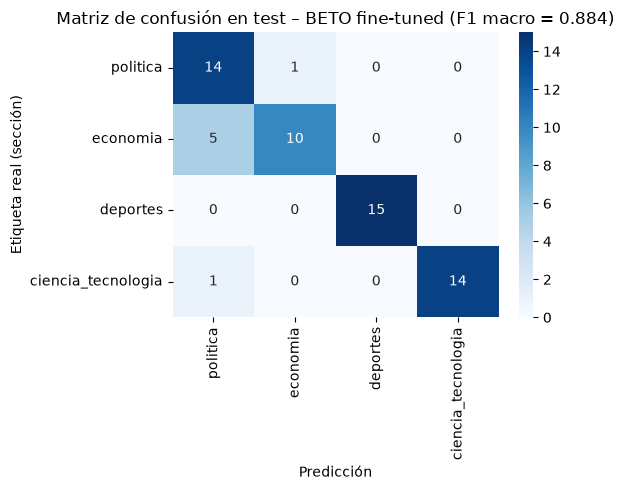

In [11]:
cm = confusion_matrix(test_df.etiqueta, test_df.pred_ft, labels=CATS)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CATS, yticklabels=CATS)
plt.xlabel("Predicción"); plt.ylabel("Etiqueta real (sección)")
plt.title(f"Matriz de confusión en test – BETO fine-tuned (F1 macro = {f1_ft:.3f})")
plt.tight_layout(); plt.show()

In [12]:
print("Errores del modelo en test:")
test_df.loc[test_df.etiqueta != test_df.pred_ft, ["titular", "etiqueta", "pred_ft"]]

Errores del modelo en test:


,titular,etiqueta,pred_ft
305,Keiko Fujimori anuncia aumento del sueldo míni...,economia,politica
273,Julio Velarde: Senado votará el 9 de septiembr...,economia,politica
38,SERFOR destina S/41 millones para fortalecer l...,politica,economia
364,Elecciones 2026: así puedes usar la IA para ev...,ciencia_tecnologia,politica
272,Presupuesto 2027: oposición cuestiona priorida...,economia,politica
373,Contraloría recomienda inicio de acciones lega...,economia,politica
234,Elmer Cuba: MEF llevará reformas económicas al...,economia,politica


### Reflexión por categoría
- **Mejor: `deportes` (F1 = 1.00).** Su léxico es muy distintivo y no se cruza con otras secciones: nombres de clubes (Alianza Lima, Universitario), torneos (Liga 1, Clausura, Copa Libertadores), “EN VIVO”, “fixture”, “vóley”. Tanto el LLM como BETO la aciertan siempre.
- **`ciencia_tecnologia` (F1 ≈ 0.97)** también se separa bien por su vocabulario (científicos, astrónomos, NASA, planeta, IA). Su único error es *“Elecciones 2026: así puedes usar la IA…”*: la palabra “Elecciones” arrastra la predicción a política.
- **Peor: `economia` (recall ≈ 0.67) y `politica` (precisión ≈ 0.70).** Casi todos los errores son **economía → política**: titulares de *política económica* que nombran a un actor político (Keiko Fujimori, el Senado, la oposición, la Contraloría, un ministro del MEF) aunque el tema sea sueldo mínimo, presupuesto o reformas económicas. El titular pone en primer plano **quién** habla y no **de qué** se habla.
- **Causa de fondo:** el LLM que generó las etiquetas de entrenamiento comete exactamente el mismo sesgo (16 notas de economía etiquetadas como política en la tabla cruzada de arriba) y el modelo ajustado lo **hereda**. Es el costo típico de la supervisión débil: el modelo aprende la frontera del etiquetador, no la del diario.

## 6. Comparativa y decisión
Se añade como referencia adicional la línea base clásica vista en clase (**TF-IDF + regresión logística**), entrenada con las mismas etiquetas del LLM.

In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline, make_union
tfidf = make_pipeline(make_union(TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True),
                                 TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True)),
                      LogisticRegression(C=10, max_iter=3000))
tfidf.fit(train_lab.titular, train_lab.etiqueta_llm)
t0 = time.perf_counter(); pred_tfidf = tfidf.predict(test_df.titular); tf_lat = (time.perf_counter() - t0) / len(test_df)
acc_tf, f1_tf = accuracy_score(test_df.etiqueta, pred_tfidf), f1_score(test_df.etiqueta, pred_tfidf, average="macro")
print(f"TF-IDF + LR en test: Accuracy={acc_tf:.3f}  F1 macro={f1_tf:.3f}")
import joblib
joblib.dump(tfidf, MODELO / "tfidf_lr.joblib")

TF-IDF + LR en test: Accuracy=0.800  F1 macro=0.800


['modelo\\tfidf_lr.joblib']

In [14]:
test_llm = df.loc[test_df.index]
acc_llm = accuracy_score(test_llm.etiqueta, test_llm.etiqueta_llm.fillna("sin_etiqueta"))
f1_llm = f1_score(test_llm.etiqueta, test_llm.etiqueta_llm.fillna("sin_etiqueta"), labels=CATS, average="macro")
ft40 = test_df.loc[zs_df.index]
lat_llm = json.load(open(MODELO / "latencia_llm.json"))["latencia_llm_s_por_titular"] if (MODELO / "latencia_llm.json").exists() else float("nan")

tabla = pd.DataFrame([
    {"modelo": "Zero-shot (BERT-es XNLI)", "evaluado_en": "40 de test", "accuracy": acc_zs, "f1_macro": f1_zs,
     "latencia_ms_titular": zs_lat * 1000, "costo": "Gratis, CPU local, 4 pasadas NLI por titular"},
    {"modelo": "LLM débil (Qwen2.5-1.5B local)", "evaluado_en": f"test completo ({len(test_df)})", "accuracy": acc_llm, "f1_macro": f1_llm,
     "latencia_ms_titular": lat_llm * 1000, "costo": "Gratis pero pesado: 1.5B parámetros (~6 GB RAM), 4 pasadas por titular"},
    {"modelo": "TF-IDF + Reg. logística", "evaluado_en": f"test completo ({len(test_df)})", "accuracy": acc_tf, "f1_macro": f1_tf,
     "latencia_ms_titular": tf_lat * 1000, "costo": "Gratis, CPU, < 5 MB"},
    {"modelo": "BETO fine-tuned", "evaluado_en": f"test completo ({len(test_df)})", "accuracy": acc_ft, "f1_macro": f1_ft,
     "latencia_ms_titular": ft_lat * 1000, "costo": "Gratis, CPU local, ~420 MB de pesos"},
    {"modelo": "BETO fine-tuned", "evaluado_en": "mismos 40 del zero-shot", "accuracy": accuracy_score(ft40.etiqueta, ft40.pred_ft),
     "f1_macro": f1_score(ft40.etiqueta, ft40.pred_ft, average="macro"), "latencia_ms_titular": ft_lat * 1000, "costo": "idem"},
]).round(3)
tabla

,modelo,evaluado_en,accuracy,f1_macro,latencia_ms_titular,costo
0,Zero-shot (BERT-es XNLI),40 de test,0.725,0.722,150.344,"Gratis, CPU local, 4 pasadas NLI por titular"
1,LLM débil (Qwen2.5-1.5B local),test completo (60),0.917,0.918,2487.894,Gratis pero pesado: 1.5B parámetros (~6 GB RAM...
2,TF-IDF + Reg. logística,test completo (60),0.800,0.800,0.161,"Gratis, CPU, < 5 MB"
3,BETO fine-tuned,test completo (60),0.883,0.884,31.613,"Gratis, CPU local, ~420 MB de pesos"
4,BETO fine-tuned,mismos 40 del zero-shot,0.925,0.926,31.613,idem


In [15]:
resumen = {"f1_macro_test": round(f1_ft, 3), "accuracy_test": round(acc_ft, 3), "f1_zero_shot": round(f1_zs, 3),
           "f1_llm_test": round(f1_llm, 3), "acuerdo_llm_humano": f"{acuerdo_n}/20", "acuerdo_llm_humano_pct": acuerdo_n / 20,
           "acuerdo_llm_seccion": round(acuerdo_seccion, 3), "n_train": len(ds_train), "n_val": len(ds_val), "n_test": len(ds_test),
           "modelo_base": BASE_MODEL, "fecha": datetime.now().strftime("%Y-%m-%d")}
json.dump(resumen, open(MODELO / "metricas.json", "w"), indent=2, ensure_ascii=False)
tabla.to_csv(MODELO / "comparativa.csv", index=False)
print(f"RESULTADOS -> F1 Macro: {f1_ft:.3f} | Zero-shot: {f1_zs:.3f} | Acuerdo LLM-Humano: {acuerdo_n}/20")

RESULTADOS -> F1 Macro: 0.884 | Zero-shot: 0.722 | Acuerdo LLM-Humano: 20/20


### Decisión para un entorno real
| Criterio | Zero-shot | LLM (Qwen 1.5B) | TF-IDF + LR | **BETO fine-tuned** |
|---|---|---|---|---|
| Precisión (F1 macro) | la más baja | la más alta | media | alta |
| Latencia por titular (CPU) | ~140 ms | ~2.4 s | < 1 ms | ~30 ms |
| Recursos | 440 MB | ~6 GB de RAM | < 5 MB | ~420 MB |

**Elegiría BETO fine-tuned para producción.** Queda a pocos puntos del LLM, pero es **~75 veces más rápido**, cabe en una laptop o un servidor pequeño sin GPU, es determinista y no depende de prompts. El LLM conviene como **etiquetador offline** (para crear o ampliar datos de entrenamiento), no para servir cada consulta en vivo. TF-IDF + LR queda como **respaldo ultraligero** (es el que usa el dashboard si no están los pesos de BETO). El zero-shot sirve solo como piso: sin ejemplos del dominio confunde mucho economía y política.

**Mejora siguiente:** corregir el sesgo economía/política del LLM (prompt con ejemplos de política económica, o mezclar etiquetas editoriales en el entrenamiento) y reentrenar.